# Assistant virtuel RAG — Hôtel Le Belvédère (Annecy)

<div align="center">
<img src="./image.png" alt="Assistant RAG Hôtel Le Belvédère" width="800"/>
</div>

> Un assistant conversationnel qui répond aux questions des clients d'un hôtel **uniquement à partir de sa documentation interne**, cite ses sources et répond « je ne sais pas » lorsque l'information n'existe pas. Pipeline 100 % local, à base de modèles open source.

## Contexte

En pleine saison estivale, l'équipe de réception d'un hôtel 42 chambres au bord du lac d'Annecy est réduite de moitié et submergée par des demandes répétitives : horaires d'arrivée, tarifs, spa, animaux acceptés, wifi… La direction souhaite automatiser ces réponses, avec une exigence non négociable :

> **L'assistant ne doit jamais inventer une information** (tarif, service, horaire) qui engagerait l'hôtel.

## Démarche

Trois stratégies sont implémentées et comparées sur le même jeu de questions :

| # | Stratégie | Principe |
|---|-----------|----------|
| 1 | **LLM seul** (baseline) | Le modèle répond à partir de ses seules connaissances |
| 2 | **Contexte complet** | Toute la documentation (≈ 1 400 mots) est injectée dans chaque prompt |
| 3 | **RAG** | Recherche sémantique des 2 rubriques les plus pertinentes, seules injectées dans le prompt |

## Résultats clés

| Stratégie | Questions factuelles correctes | Refus d'une question hors périmètre | Contexte envoyé | Temps (4 questions, CPU) |
|-----------|:---:|:---:|:---:|:---:|
| LLM seul | ❌ hallucinations (« hôtel 5 étoiles à Paris ») | — | 0 mot | — |
| Contexte complet | 1 / 3 | ✅ | 1 415 mots | 873 s |
| **RAG (top-2)** | **3 / 3** | ✅ | **≈ 210 mots** | **144 s** |

**Le RAG divise par ~6 le temps de réponse et par ~7 la taille du contexte, tout en corrigeant les erreurs de l'approche « contexte complet ».**

## Stack technique

`Python 3.13` · `transformers` (Qwen2.5-0.5B-Instruct) · `sentence-transformers` (paraphrase-multilingual-MiniLM-L12-v2) · `pypdf` · `numpy` · `pandas` · `scikit-learn` (t-SNE) · `matplotlib`

## Sommaire

1. [Configuration](#1.-Configuration)
2. [Baseline : le LLM seul hallucine](#2.-Baseline-:-le-LLM-seul-hallucine)
3. [Ingestion des documents PDF](#3.-Ingestion-des-documents-PDF)
4. [Approche 1 : toute la documentation dans le prompt](#4.-Approche-1-:-toute-la-documentation-dans-le-prompt)
5. [Indexation vectorielle (embeddings)](#5.-Indexation-vectorielle-(embeddings))
6. [Approche 2 : pipeline RAG](#6.-Approche-2-:-pipeline-RAG)
7. [Synthèse et analyse](#7.-Synthèse-et-analyse)
8. [Limites et perspectives](#8.-Limites-et-perspectives)

## 1. Configuration

Deux modèles pré-entraînés sont téléchargés depuis Hugging Face au premier lancement (≈ 1,5 Go, mis en cache ensuite) :

- **Génération** : `Qwen/Qwen2.5-0.5B-Instruct`, petit LLM conversationnel multilingue (≈ 500 M paramètres), volontairement léger pour tourner sur CPU.
- **Embeddings** : `paraphrase-multilingual-MiniLM-L12-v2`, encodeur de phrases multilingue (vecteurs de dimension 384), adapté à une documentation rédigée en français.

La génération est **déterministe** (`do_sample=False`) afin de rendre les expériences reproductibles.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE
from transformers import pipeline

from utils import print_chat

transformers.logging.set_verbosity_error()

# --- Paramètres du projet ---------------------------------------------------
DATA_DIR = Path("data")
LLM_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
EMBEDDING_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MAX_NEW_TOKENS = 80   # longueur maximale d'une réponse (≈ 60 mots)
TOP_K = 2             # nombre de rubriques injectées dans le prompt RAG

## 2. Baseline : le LLM seul hallucine

Avant toute construction, on mesure le comportement d'un LLM généraliste interrogé sur l'hôtel **sans aucune information de contexte**.

In [2]:
generator = pipeline("text-generation", model=LLM_MODEL)


def ask_llm(prompt):
    """Envoie un message au LLM et retourne sa réponse (génération déterministe)."""
    conversation = generator(
        [{"role": "user", "content": prompt}],
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,
    )
    return conversation[0]["generated_text"][-1]["content"]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

In [3]:
baseline_questions = [
    "A quelle heure puis-je faire mon check-in a l'Hotel Le Belvedere ?",
    "Est-ce qu'il y a un spa a l'Hotel Le Belvedere ?",
]

for question in baseline_questions:
    print_chat(question, ask_llm(question))

Client   : A quelle heure puis-je faire mon check-in a l'Hotel Le Belvedere ?
Assistant: Pour effectuer votre check-in à l'hôtel Le Belvedere, vous devrez suivre les instructions de la plateforme d'hébergement. Voici comment vous pouvez procéder :

1. Vérifiez si le site web ou le site officiel du hotel est disponible pour l'heure que vous souhaitez.

2. Si le site est disponible, inscrive
--------------------------------------------------------------------------------
Client   : Est-ce qu'il y a un spa a l'Hotel Le Belvedere ?
Assistant: Oui, il existe un spa à l'hôtel Le Belvedere. Le Belvedere est une propriété de luxe située dans le centre-ville de Paris, France. Il s'agit d'un hôtel de 5 étoiles qui offre des services de qualité pour les clients.

Le spa de l'hôtel Le Belvedere comprend plusieurs atouts :

1. Une pisc
--------------------------------------------------------------------------------


**Constat.** La première réponse est un tutoriel générique sans rapport avec l'hôtel. La seconde affirme avec assurance que l'établissement est un « hôtel 5 étoiles situé dans le centre-ville de Paris » : **faux** (l'hôtel est à Annecy et n'a aucune classification mentionnée). L'existence d'un spa est correcte, mais par pur hasard statistique.

C'est le risque métier identifié par le client : un modèle qui devine avec la même assurance lorsqu'il a raison et lorsqu'il se trompe est **inutilisable en production**. Il faut l'ancrer dans la documentation réelle de l'hôtel.

## 3. Ingestion des documents PDF

La documentation fournie se compose de **5 fichiers PDF** rédigés par la réception (informations pratiques, chambres et tarifs, restauration et bien-être, familles/animaux/accessibilité, activités et événements).

Chaque page correspond à une rubrique thématique avec une structure constante :
- **1re ligne** : titre de la rubrique ;
- **dernière ligne** : pied de page répété (adresse, numéro de page), sans valeur informative → supprimé.

Chaque rubrique est ensuite mise en forme en **Markdown** (`## Titre` + texte) : ce format structuré aide le LLM à se repérer dans le contexte, et c'est aussi le texte qui sera vectorisé à l'étape d'indexation. Les rubriques étant courtes et autonomes, **une page = un chunk**.

In [4]:
def load_documentation(data_dir):
    """Extrait chaque page des PDF du dossier en une rubrique (source, titre, texte, section Markdown)."""
    rows = []
    for path in sorted(Path(data_dir).glob("*.pdf")):
        for page in PdfReader(path).pages:
            lines = page.extract_text().split("\n")
            rows.append({
                "source": path.name,
                "title": lines[0],                 # titre de la rubrique
                "text": "\n".join(lines[1:-1]),   # contenu sans titre ni pied de page
            })
    docs = pd.DataFrame(rows)
    docs["section"] = "## " + docs["title"] + "\n\n" + docs["text"]
    return docs


pages = load_documentation(DATA_DIR)
print(f"{len(pages)} rubriques extraites des {pages['source'].nunique()} PDF")
display(pages[["source", "title", "text"]])

15 rubriques extraites des 5 PDF


,source,title,text
0,activites_et_evenements.pdf,Activités et alentours,L'hôtel loue des vélos électriques à l'accueil...
1,activites_et_evenements.pdf,Séminaires et événements,"L'hôtel dispose de deux salles de séminaire, p..."
2,chambres_et_tarifs.pdf,Chambres et tarifs,L'hôtel propose 42 chambres réparties en quatr...
3,chambres_et_tarifs.pdf,Politique d'annulation et de paiement,L'annulation est gratuite jusqu'à 48h avant la...
4,chambres_et_tarifs.pdf,Climatisation et confort des chambres,Toutes les chambres de l'hôtel sont climatisée...
5,familles_animaux_accessibilite.pdf,Familles et enfants,Les lits bébé et les chaises hautes sont fourn...
6,familles_animaux_accessibilite.pdf,Animaux domestiques,Les animaux domestiques de moins de 10 kg sont...
7,familles_animaux_accessibilite.pdf,Accessibilité PMR,L'hôtel dispose de 4 chambres adaptées aux per...
8,informations_pratiques.pdf,Horaires de la réception,La réception de l'Hôtel Le Belvédère est ouver...
9,informations_pratiques.pdf,Wifi et connexion internet,Le wifi est gratuit et illimité dans toutes le...


## 4. Approche 1 : toute la documentation dans le prompt

Première stratégie : concaténer toutes les rubriques et les injecter dans chaque prompt. Le prompt est structuré en quatre blocs :

1. **Rôle** de l'assistant ;
2. **Contexte** documentaire ;
3. **Question** du client ;
4. **Consigne anti-hallucination** : répondre uniquement à partir du contexte, sinon renvoyer une phrase de repli fixe vers la réception.

Le jeu de test comporte trois questions dont la réponse figure dans la documentation, et une **question hors périmètre** (paiement en Bitcoin) pour vérifier que l'assistant refuse de répondre.

In [5]:
ROLE = (
    "Tu es l'assistant virtuel de l'Hôtel Le Belvédère, au bord du lac d'Annecy.\n"
    "Voici la documentation officielle de l'hôtel :"
)

CONSIGNE = (
    "Réponds en une ou deux phrases, uniquement à partir des informations "
    "de la documentation ci-dessus. Si l'information ne s'y trouve pas, réponds exactement : "
    '"Je ne sais pas, je vous invite à contacter la réception."'
)


def build_prompt(context, question):
    """Assemble le prompt : rôle, contexte, question du client, consigne."""
    return f"{ROLE}\n\n{context}\n\nQuestion d'un client : {question}\n{CONSIGNE}"


full_context = "\n\n".join(pages["section"])
print(f"Taille de la documentation complète : {len(full_context.split())} mots")

Taille de la documentation complète : 1415 mots


In [6]:
questions_hotel = [
    "A quelle heure commence le check-in ?",                    # réponse attendue : 7h-22h
    "Le wifi est-il gratuit ?",                                 # réponse attendue : je ne sais pas
    "Combien coute une chambre Classique en basse saison ?",    # réponse attendue : 120 € / nuit
    "Est-ce que vous acceptez les paiements en Bitcoin ?",      # hors périmètre : refus attendu
]

start = time.time()
for question in questions_hotel:
    answer = ask_llm(build_prompt(full_context, question))
    print(f"{question}\n{answer}\n")
print(f"Temps total : {time.time() - start:.0f} secondes pour {len(questions_hotel)} questions")

A quelle heure commence le check-in ?
La réception de l'Hôtel Le Belvédère est ouverte tous les jours de 7h à 22h.

Le wifi est-il gratuit ?
Je ne sais pas, je vous invite à contacter la réception.

Combien coute une chambre Classique en basse saison ?
Une chambre Classique en basse saison coûte 120 euros par nuit.

Est-ce que vous acceptez les paiements en Bitcoin ?
Je ne sais pas, je vous invite à contacter la réception.

Temps total : 799 secondes pour 4 questions


**Analyse.**

| Question | Résultat | Diagnostic |
|---|---|---|
| Check-in | ❌ « 7h à 22h » | Horaires de la *réception* : bonne rubrique, mauvaise phrase |
| Wifi | ❌ « Je ne sais pas » | Information présente mais non retrouvée dans un long contexte |
| Chambre Classique | ✅ 120 € | — |
| Bitcoin | ✅ refus | La consigne anti-hallucination fonctionne |

Les hallucinations ont disparu, mais un contexte de 1 400 mots **dilue l'attention** d'un petit modèle, et le temps de calcul explose (≈ 3,6 min par question sur CPU). À l'échelle d'une entreprise réelle (milliers de documents, milliers de requêtes/jour, données confidentielles), cette approche se heurte à trois limites : **taille de la fenêtre de contexte, coût au token et confidentialité**.

## 5. Indexation vectorielle (embeddings)

Le principe du RAG (*Retrieval-Augmented Generation*) : avant de générer, **retrouver uniquement les passages pertinents**.

```
Question → Embedding → Recherche des k rubriques les plus proches → Prompt (mini-contexte + question) → LLM → Réponse + sources
```

Une recherche par mots-clés échouerait dès que le client n'emploie pas le vocabulaire de la documentation (« chiens » vs « animaux domestiques »). On utilise donc une **recherche sémantique** : chaque texte est transformé en vecteur de 384 dimensions qui encode son sens. Les vecteurs étant normalisés, la **similarité cosinus** se réduit à un produit scalaire.

In [7]:
embedder = SentenceTransformer(EMBEDDING_MODEL)

dimension = embedder.encode(["Bonjour"]).shape[1]
print(f"Modèle d'embedding chargé : chaque texte devient un vecteur de {dimension} nombres")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modèle d'embedding chargé : chaque texte devient un vecteur de 384 nombres


**Vérification rapide** : deux phrases de même sens mais sans vocabulaire commun doivent être proches, une phrase hors sujet doit être éloignée.

In [8]:
phrases = [
    "La piscine est chauffée à 27 degrés.",
    "Quelle est la température de l'eau de la piscine ?",
    "Le petit-déjeuner est servi jusqu'à 10h30.",
]

vecteurs = embedder.encode(phrases, normalize_embeddings=True)
print("Forme de la matrice de vecteurs :", vecteurs.shape)

print(f"\nSimilarité (piscine / température de l'eau) : {vecteurs[0] @ vecteurs[1]:.3f}")
print(f"Similarité (piscine / petit-déjeuner)        : {vecteurs[0] @ vecteurs[2]:.3f}")

Forme de la matrice de vecteurs : (3, 384)

Similarité (piscine / température de l'eau) : 0.729
Similarité (piscine / petit-déjeuner)        : 0.026


Les embeddings capturent bien le sens (0,73 contre 0,03). On vectorise ensuite les 15 rubriques **une seule fois** : cette matrice constitue l'index vectoriel. À chaque requête, seule la question est encodée.

> Avec 15 chunks, une matrice `numpy` suffit. En production, on utiliserait une base vectorielle (FAISS, Chroma, Qdrant, pgvector…) pour indexer des millions de vecteurs.

In [9]:
chunk_embeddings = embedder.encode(pages["section"].tolist(), normalize_embeddings=True)

print(f"Index vectoriel : {chunk_embeddings.shape[0]} vecteurs de dimension {chunk_embeddings.shape[1]}")

Index vectoriel : 15 vecteurs de dimension 384


### Visualisation de l'espace sémantique (t-SNE)

Projection 2D des 15 vecteurs pour contrôler la cohérence de l'index. Sans aucune supervision, des regroupements thématiques émergent : **séjour et bien-être** (piscine, spa, familles, climatisation) d'un côté, **services pratiques** (petit-déjeuner, blanchisserie, réception, annulation) de l'autre.

*Seules les proximités relatives sont interprétables ; les axes n'ont pas de signification.*

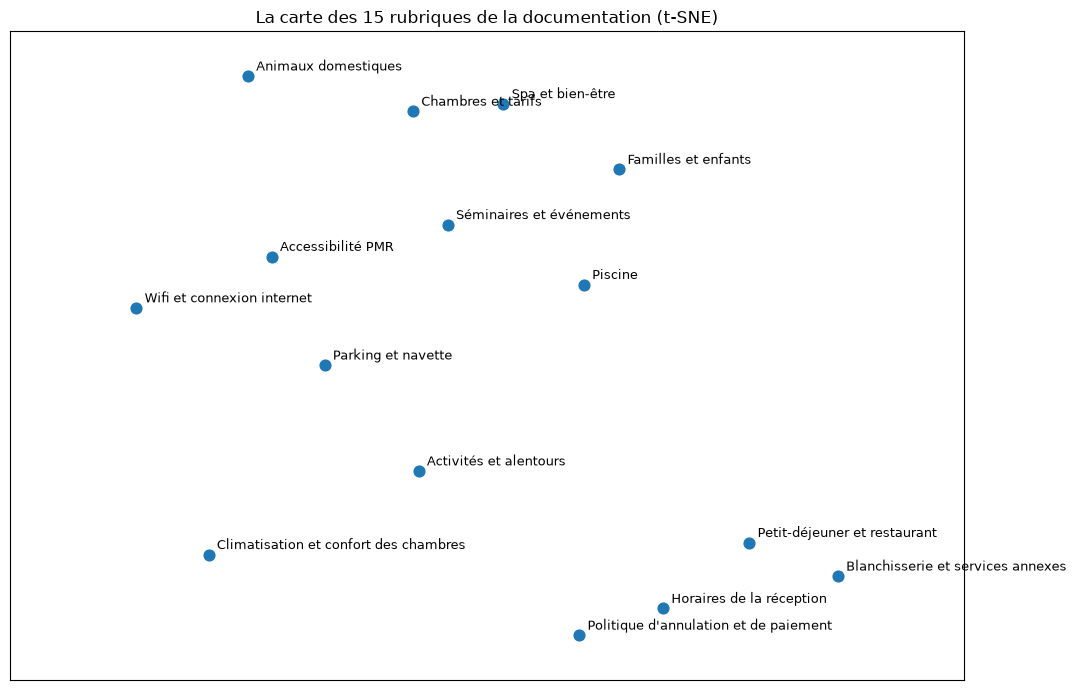

In [10]:
coords = TSNE(n_components=2, perplexity=5, random_state=42).fit_transform(chunk_embeddings)

plt.figure(figsize=(11, 7))
plt.scatter(coords[:, 0], coords[:, 1], s=60)
for i, row in pages.iterrows():
    plt.annotate(row["title"], (coords[i, 0], coords[i, 1]),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
plt.title("La carte des 15 rubriques de la documentation (t-SNE)")
plt.xticks([])
plt.yticks([])
plt.margins(x=0.18, y=0.08)
plt.tight_layout()
plt.show()

## 6. Approche 2 : pipeline RAG

### 6.1 Retrieval

La fonction `search` encode la question, calcule sa similarité avec les 15 rubriques et retourne les `top_k` plus proches avec leur score.

In [11]:
def search(question, top_k=TOP_K):
    """Retourne les top_k rubriques les plus proches de la question, triées par score décroissant."""
    question_embedding = embedder.encode([question], normalize_embeddings=True)[0]
    similarities = chunk_embeddings @ question_embedding
    top_indices = np.argsort(-similarities)[:top_k]

    results = pages.iloc[top_indices].copy()
    results["score"] = similarities[top_indices]
    return results


display(search("Est-ce qu'il y a une piscine ?")[["source", "title", "score"]])

,source,title,score
13,restaurant_et_bien_etre.pdf,Piscine,0.570319
5,familles_animaux_accessibilite.pdf,Familles et enfants,0.329833


### 6.2 Génération augmentée

Le pipeline complet réutilise les briques précédentes : `search` → mini-contexte Markdown → `build_prompt` (**même prompt** qu'à l'approche 1, seul le contexte change) → `ask_llm`. Les rubriques utilisées sont retournées pour **citer les sources** de chaque réponse.

In [12]:
def answer_question(question, top_k=TOP_K):
    """Pipeline RAG complet : retourne la réponse générée et les rubriques utilisées comme sources."""
    retrieved = search(question, top_k)
    context = "\n\n".join(retrieved["section"])
    answer = ask_llm(build_prompt(context, question))
    return answer, retrieved

### 6.3 Évaluation sur le jeu de test

In [13]:
start = time.time()
for question in questions_hotel:
    answer, sources = answer_question(question)
    print_chat(question, answer, sources)
print(f"Temps total : {time.time() - start:.0f} secondes pour {len(questions_hotel)} questions")

Client   : A quelle heure commence le check-in ?
Sources  : Horaires de la réception (0.59), Politique d'annulation et de paiement (0.53)
Assistant: Le check-in commence à 15h.
--------------------------------------------------------------------------------
Client   : Le wifi est-il gratuit ?
Sources  : Wifi et connexion internet (0.65), Politique d'annulation et de paiement (0.26)
Assistant: Le wifi est gratuit et illimité dans toutes les chambres et dans les parties communes de l'hôtel. Il est également disponible sur le réseau Belvedere_Guest.
--------------------------------------------------------------------------------
Client   : Combien coute une chambre Classique en basse saison ?
Sources  : Chambres et tarifs (0.57), Climatisation et confort des chambres (0.45)
Assistant: 120 euros
--------------------------------------------------------------------------------
Client   : Est-ce que vous acceptez les paiements en Bitcoin ?
Sources  : Politique d'annulation et de paiement (0.2

In [14]:
retrieved = search(questions_hotel[0])
rag_context = "\n\n".join(retrieved["section"])

print(f"Contexte – approche 1 (complet) : {len(full_context.split()):>5} mots (toute la documentation)")
print(f"Contexte – approche 2 (RAG)     : {len(rag_context.split()):>5} mots (les {len(retrieved)} rubriques les plus pertinentes)")

Contexte – approche 1 (complet) :  1415 mots (toute la documentation)
Contexte – approche 2 (RAG)     :   213 mots (les 2 rubriques les plus pertinentes)


## 7. Synthèse et analyse

| Question | LLM + contexte complet | **RAG (top-2)** |
|---|---|---|
| Check-in | ❌ 7h–22h | ✅ 15h |
| Wifi | ❌ « Je ne sais pas » | ✅ gratuit et illimité |
| Chambre Classique (basse saison) | ✅ 120 € | ✅ 120 € |
| Bitcoin (hors périmètre) | ✅ refus | ✅ refus |
| **Temps total (4 questions)** | 873 s | **144 s (≈ ×6)** |
| **Contexte moyen** | 1 415 mots | **≈ 210 mots (≈ ×7 moins)** |

**Enseignements**

- **Moins de contexte, meilleures réponses** : un contexte ciblé réduit les distractions du modèle, le coût en tokens et la latence, et rend la solution indépendante de la taille du corpus (15 ou 15 000 rubriques, le LLM n'en lit que 2).
- **Traçabilité** : chaque réponse est accompagnée de ses sources et de leur score, ce qui permet à la réception de vérifier l'information instantanément.
- **Détection du hors-périmètre** : la question Bitcoin obtient des scores de similarité nettement plus faibles (0,27 / 0,18) que les questions couvertes (0,57 – 0,65). Ce signal peut servir de **seuil de rejet** avant même d'appeler le LLM.

## 8. Limites et perspectives

**Limites du prototype**

- **Taille du LLM** : 0,5 B paramètres, choisi pour tourner sur CPU. Le retrieval est fiable (« chiens » retrouve bien « Animaux domestiques »), mais la génération reste parfois maladroite ou trop prudente quand la formulation diffère de la documentation.
- **Évaluation limitée** : 4 questions de test. Une mise en production nécessiterait un jeu d'évaluation annoté et des métriques dédiées.
- **Chunking trivial** : les rubriques courtes rendent le découpage « une page = un chunk » suffisant, ce qui ne serait pas le cas sur des documents longs.

**Pistes d'amélioration**

- Base vectorielle (**FAISS**, **Chroma**) et benchmark de latence sur un corpus volumineux.
- LLM plus performant (Qwen 7B, Mistral, ou API type Claude) et comparaison qualitative.
- Chunking avec recouvrement (*overlap*) pour des documents longs.
- Évaluation quantitative : **recall@k** pour le retrieval, **fidélité au contexte** pour la génération.
- Seuil de similarité pour rejeter les questions hors périmètre sans solliciter le LLM.
- Interface de chat (**Gradio** / **Streamlit**) avec mémoire conversationnelle.